### Run this notebook online

[![Open in Colab](https://img.shields.io/badge/Open_in-Colab-F9AB00?logo=googlecolab&logoColor=F9AB00)](https://colab.research.google.com/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT.ipynb)
[![Open in Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://www.kaggle.com/kernels/welcome?src=https%3A%2F%2Fgithub.com%2Fhosein-fanai%2FContinual-Learning-with-Diffusion-Vision-Transformers%2Fblob%2Fmain%2Ffiles%2Fnotebooks%2FCIFAR10%2520DiT.ipynb)
[![Launch Binder](https://img.shields.io/badge/launch-binder-F5793A?logo=jupyter&logoColor=white)](https://mybinder.org/v2/gh/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/main?urlpath=lab%2Ftree%2Ffiles%2Fnotebooks%2FCIFAR10%20DiT.ipynb)

- **Google Colab:** open the notebook, select a GPU for training under **Runtime > Change runtime type**, then choose **Run all**.
- **Kaggle:** sign in and import the notebook, enable **Internet**, select a **GPU** accelerator for training, then **Run all**.
- **Binder:** opens a temporary CPU JupyterLab session. Use it to inspect the notebook or run small checks; full training needs more resources.
- **[Studio Lab](https://studiolab.sagemaker.aws/import/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT.ipynb) (existing accounts only):** start a runtime, copy the notebook to your project, select a Python **3.11–3.13** kernel, and set `RUNTIME = "studiolab"` in the first code cell before **Run all**. For CPU, also set `CUDA = False`.

The **first code cell** finds or downloads the repository and prepares TensorFlow **2.20** / Keras **3.11.2** before project imports. If setup requests a restart, restart the kernel and run all again. For another hosted Jupyter service, set `RUNTIME = "hosted"` (`CUDA = False` for CPU or compatible provider-managed CUDA). Locally, select the project TensorFlow kernel.

Launch links open the published GitHub `main` version; publish this notebook and its setup files together before using them. For a notebook that has not been published, upload its `.ipynb` file to Colab or Kaggle instead. GPU availability depends on the provider. Save checkpoints and results before a temporary session ends.

See the [hosted runtime guide](https://github.com/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/thesis/README.md#hosted-runtimes) for setup and import details.


In [1]:
import os
import tensorflow as tf
import keras


if tf.__version__ != "2.20.0" or keras.__version__ != "3.11.2":
    raise RuntimeError("Unexpected framework version.")
physical_gpus = tf.config.list_physical_devices("GPU")
if len(physical_gpus) != 1:
    raise RuntimeError("One admitted GPU is required.")
tf.config.set_logical_device_configuration(physical_gpus[0], [tf.config.LogicalDeviceConfiguration(memory_limit=24576)])
print({"pid": os.getpid(), "tensorflow": tf.__version__, "keras": keras.__version__, "gpu_cap_mib": 24576})


2026-10-11 11:30:10.676735: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-11 11:30:10.728106: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-10-11 11:30:11.928627: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


{'pid': 157195, 'tensorflow': '2.20.0', 'keras': '3.11.2', 'gpu_cap_mib': 24576}


In [2]:
"""Prepare a notebook checkout and runtime before importing scientific packages.

This canonical first-cell source is copied into maintained notebooks and generated
HPO notebooks. Edit REVISION/RUNTIME/CUDA before execution when needed. Existing
checkouts are reused without fetching; only missing setup code is downloaded.
ROOT is the selected absolute pathlib.Path; RUNTIME_PACKAGES maps package names
to installed version strings. Preparation may clone/install under the selected
policy and changes cwd/import paths through files.notebooks.init.prepare_notebook.
"""
from pathlib import Path
from urllib.request import urlopen


CHECKOUT_NAME = "Continual-Learning-with-Diffusion-Vision-Transformers"
REPOSITORY = f"https://github.com/hosein-fanai/{CHECKOUT_NAME}.git"
REVISION = "main"
RUNTIME = "local"  # Use "hosted" for another online service, or "local" to verify only.
CUDA = None  # False: CPU or managed CUDA; True: retain CUDA pip dependencies.

_locations = (Path.cwd(), *Path.cwd().parents, Path.cwd() / CHECKOUT_NAME, 
              Path("/kaggle/working") / CHECKOUT_NAME, Path("/content") / CHECKOUT_NAME)
_initializer = next((path / "files" / "notebooks" / "init.py" for path in _locations
                     if (path / "files" / "notebooks" / "init.py").is_file()), None)
_url = f"https://raw.githubusercontent.com/hosein-fanai/{CHECKOUT_NAME}/{REVISION}/files/notebooks/init.py"
_setup = {"__name__": "notebook_setup", "__file__": str(_initializer or _url)}
with (_initializer.open("rb") if _initializer else urlopen(_url, timeout=30)) as _file:
    exec(compile(_file.read(), _setup["__file__"], "exec"), _setup)
ROOT, RUNTIME_PACKAGES = _setup["prepare_notebook"](
    checkout_name=CHECKOUT_NAME, 
    repository=REPOSITORY, 
    revision=REVISION, 
    runtime=RUNTIME, 
    cuda=CUDA
)


Repository ready: /workspace/cifar10_dit_three_v2_20261011/source (runtime: local)


Runtime packages ready: Python 3.12.3, TensorFlow 2.20.0, Keras 3.11.2


In [3]:
from common import utils


utils.init()

## Experiment settings


In [4]:
epochs = 50
val_freq = 5

## CIFAR10 data


In [5]:
from common.dataloader import load_cifar10, get_dataset


x_train, y_train, _, _, x_test, y_test = load_cifar10(
    indices=None, 
    validation_ratio=0.0, 
    verbose=0
)

trainset = get_dataset(x_train, y_train.reshape(-1), batch_size=64)
valset = get_dataset(x_test, y_test.reshape(-1), shuffle_buffer=0, batch_size=64, drop_remainder=False)

2026-10-11 11:30:22.005891: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1791718222.007367  157195 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 24576 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:13:00.0, compute capability: 8.0


## DiT denoiser


In [6]:
from diffusion.models.transformer.diffusion_transformer import DiffusionTransformer
from diffusion.models.wrapper.diffusion_model import DiffusionModel


vit = DiffusionTransformer(
    image_size=32, 
    channels=3, 
    dim=96, 
    depth=6, 
    mha_num_heads=4, 
    patchify_with_cnn=True, 
    use_refiner_cnn=False, 
    vit_block_mlp_ratio=2.0
)
model = DiffusionModel(network=vit, p_uncond=0.2, image_loss_coef=0.05)

vit.summary()

Model: "diffusion_transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ depth_0_patch_embedder          │ (None, 256, 96)        │        42,912 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_embedder           │ (None, 96)             │        96,000 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_label_embedder          │ (None, 96)             │         1,056 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_label_merger (Add) │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_1_encoder_block           │ (None, 256, 96)        │       130,278 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_2_encoder_block           │ (None, 256, 96)        │       130,278 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_3_encoder_block           │ (None, 256, 96)        │       130,278 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_4_encoder_block           │ (None, 256, 96)        │       130,278 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_5_encoder_block           │ (None, 256, 96)        │       130,278 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_6_encoder_block           │ (None, 256, 96)        │       130,278 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unpatchifier (Functional)       │ (None, 32, 32, 3)      │        19,788 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 941,424 (3.59 MB)

 Trainable params: 845,388 (3.22 MB)

 Non-trainable params: 96,036 (375.28 KB)

## Optimizer


In [7]:
from tensorflow.keras import optimizers


lr_schedule = optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0038474121991684505, # 5e-3
    decay_steps=epochs * len(trainset)
)

model.compile(
    optimizer=optimizers.Adam(lr_schedule, global_clipnorm=0.5), 
    loss="mse"
)

In [8]:
from tensorflow.keras import callbacks

from common.callbacks.lr_logger import LrLogger

from diffusion.callbacks.image_generator import ImageGenerator


callbacks_list = [
    LrLogger(), 
    callbacks.ProgbarLogger(), 
    ImageGenerator(frequency=val_freq)
]

callbacks_list.append(callbacks.CSVLogger('/workspace/cifar10_dit_three_v2_20261011/notebook-3/training.csv'))


## Training


Epoch 1/50


2026-10-11 11:30:37.734699: I external/local_xla/xla/service/service.cc:163] XLA service 0x7167c40151a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-11 11:30:37.734728: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA A100-SXM4-80GB, Compute Capability 8.0


2026-10-11 11:30:38.181250: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


2026-10-11 11:30:43.974133: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002


2026-10-11 11:30:45.155393: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-11 11:30:45.155556: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-11 11:30:45.155854: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

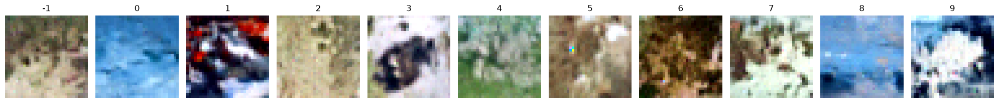

Epoch 6/50


  1/781 ━━━━━━━━━━━━━━━━━━━━ 1:22 105ms/step - image_loss: 0.0811 - loss: 0.0332 - noise_loss: 0.0292

  3/781 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - image_loss: 0.0929 - loss: 0.0331 - noise_loss: 0.0284  

  6/781 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - image_loss: 0.0914 - loss: 0.0334 - noise_loss: 0.0289

  8/781 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - image_loss: 0.0915 - loss: 0.0336 - noise_loss: 0.0290

...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

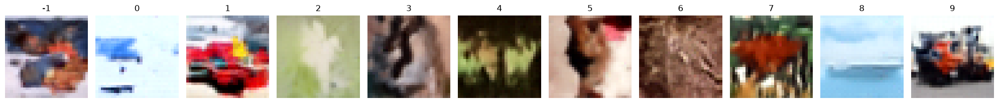

Epoch 11/50


  1/781 ━━━━━━━━━━━━━━━━━━━━ 58s 74ms/step - image_loss: 0.1356 - loss: 0.0384 - noise_loss: 0.0316

  3/781 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - image_loss: 0.1289 - loss: 0.0370 - noise_loss: 0.0306

  6/781 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - image_loss: 0.1160 - loss: 0.0357 - noise_loss: 0.0299

  9/781 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - image_loss: 0.1088 - loss: 0.0352 - noise_loss: 0.0298

...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

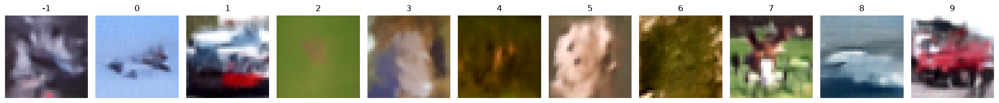

Epoch 16/50


  1/781 ━━━━━━━━━━━━━━━━━━━━ 59s 77ms/step - image_loss: 0.0725 - loss: 0.0308 - noise_loss: 0.0272

  3/781 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - image_loss: 0.0681 - loss: 0.0315 - noise_loss: 0.0281

  6/781 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - image_loss: 0.0655 - loss: 0.0328 - noise_loss: 0.0295

  8/781 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - image_loss: 0.0648 - loss: 0.0330 - noise_loss: 0.0297

...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

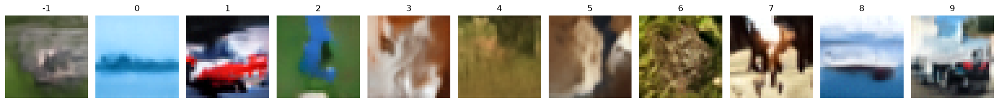

Epoch 21/50


  1/781 ━━━━━━━━━━━━━━━━━━━━ 1:00 78ms/step - image_loss: 0.0580 - loss: 0.0339 - noise_loss: 0.0310

  3/781 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - image_loss: 0.0669 - loss: 0.0317 - noise_loss: 0.0284 

  5/781 ━━━━━━━━━━━━━━━━━━━━ 19s 26ms/step - image_loss: 0.0676 - loss: 0.0317 - noise_loss: 0.0283

  7/781 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - image_loss: 0.0676 - loss: 0.0317 - noise_loss: 0.0283

...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

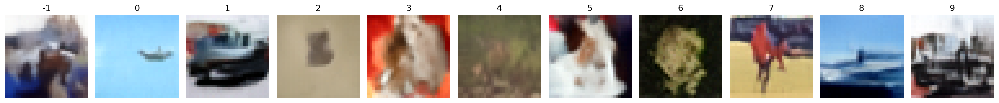

Epoch 26/50


  1/781 ━━━━━━━━━━━━━━━━━━━━ 1:05 84ms/step - image_loss: 0.0519 - loss: 0.0317 - noise_loss: 0.0291

  3/781 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - image_loss: 0.0578 - loss: 0.0323 - noise_loss: 0.0294 

  5/781 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - image_loss: 0.0600 - loss: 0.0322 - noise_loss: 0.0292

  8/781 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - image_loss: 0.0613 - loss: 0.0321 - noise_loss: 0.0290

...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

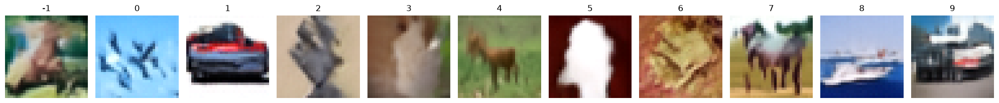

Epoch 31/50


  1/781 ━━━━━━━━━━━━━━━━━━━━ 1:01 79ms/step - image_loss: 0.0847 - loss: 0.0313 - noise_loss: 0.0271

  3/781 ━━━━━━━━━━━━━━━━━━━━ 19s 26ms/step - image_loss: 0.0749 - loss: 0.0317 - noise_loss: 0.0280 

  5/781 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - image_loss: 0.0721 - loss: 0.0323 - noise_loss: 0.0286

  8/781 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - image_loss: 0.0719 - loss: 0.0324 - noise_loss: 0.0288

...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

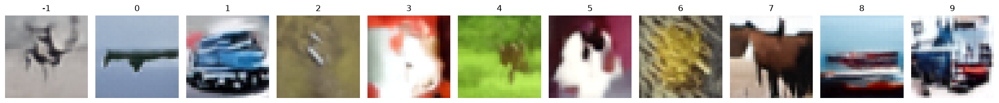

Epoch 36/50


  1/781 ━━━━━━━━━━━━━━━━━━━━ 1:02 80ms/step - image_loss: 0.0627 - loss: 0.0357 - noise_loss: 0.0326

  4/781 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - image_loss: 0.0640 - loss: 0.0325 - noise_loss: 0.0293 

  6/781 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - image_loss: 0.0653 - loss: 0.0319 - noise_loss: 0.0286

  9/781 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - image_loss: 0.0649 - loss: 0.0314 - noise_loss: 0.0282

...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

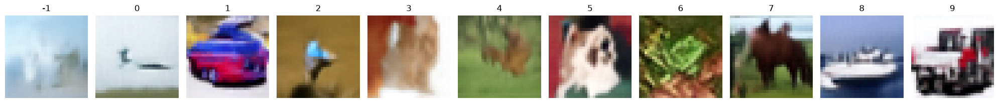

Epoch 41/50


  1/781 ━━━━━━━━━━━━━━━━━━━━ 1:00 77ms/step - image_loss: 0.0629 - loss: 0.0263 - noise_loss: 0.0232

  4/781 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - image_loss: 0.0601 - loss: 0.0293 - noise_loss: 0.0263 

  7/781 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - image_loss: 0.0608 - loss: 0.0299 - noise_loss: 0.0268

 10/781 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - image_loss: 0.0618 - loss: 0.0299 - noise_loss: 0.0268

...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

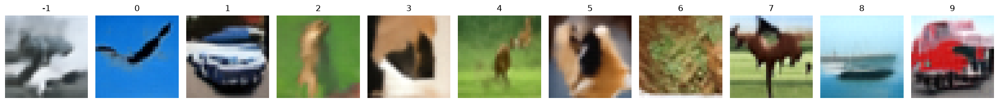

Epoch 46/50


  1/781 ━━━━━━━━━━━━━━━━━━━━ 1:01 78ms/step - image_loss: 0.0574 - loss: 0.0289 - noise_loss: 0.0260

  4/781 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - image_loss: 0.0617 - loss: 0.0297 - noise_loss: 0.0267 

  7/781 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - image_loss: 0.0609 - loss: 0.0310 - noise_loss: 0.0279

  9/781 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - image_loss: 0.0610 - loss: 0.0313 - noise_loss: 0.0282

...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

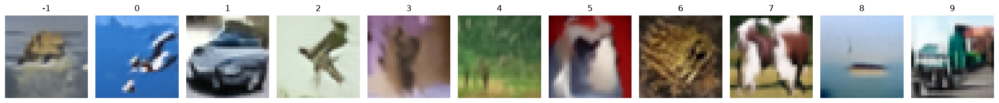

In [9]:
history = model.fit(
    trainset, 
    epochs=epochs, 
    validation_data=valset, 
    callbacks=callbacks_list, 
    validation_freq=val_freq
).history

## Save weights


In [10]:
model.save_weights("/workspace/cifar10_dit_three_v2_20261011/notebook-3/model.weights.h5")

## Evaluate EMA and raw networks


In [11]:
model.evaluate(valset, network_name="ema")

  1/157 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - image_loss: 0.0834 - loss: 0.0329 - noise_loss: 0.0287

  5/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - image_loss: 0.0858 - loss: 0.0345 - noise_loss: 0.0302

  9/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - image_loss: 0.0834 - loss: 0.0349 - noise_loss: 0.0308

 13/157 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - image_loss: 0.0822 - loss: 0.0350 - noise_loss: 0.0309

 17/157 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - image_loss: 0.0817 - loss: 0.0350 - noise_loss: 0.0309

...

141/157 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - image_loss: 0.0769 - loss: 0.0351 - noise_loss: 0.0312

148/157 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - image_loss: 0.0769 - loss: 0.0351 - noise_loss: 0.0312

155/157 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - image_loss: 0.0768 - loss: 0.0351 - noise_loss: 0.0312

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - image_loss: 0.0759 - loss: 0.0349 - noise_loss: 0.0311


[<tf.Tensor: shape=(), dtype=float32, numpy=0.03490714356303215>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.031111299991607666>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.07591657340526581>]

In [12]:
model.evaluate(valset, network_name="raw")

  1/157 ━━━━━━━━━━━━━━━━━━━━ 17:07 7s/step - image_loss: 0.0722 - loss: 0.0380 - noise_loss: 0.0344

  5/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - image_loss: 0.0754 - loss: 0.0366 - noise_loss: 0.0328 

  9/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - image_loss: 0.0767 - loss: 0.0356 - noise_loss: 0.0318

 13/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - image_loss: 0.0766 - loss: 0.0353 - noise_loss: 0.0315

 17/157 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - image_loss: 0.0763 - loss: 0.0354 - noise_loss: 0.0315

...

143/157 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - image_loss: 0.0766 - loss: 0.0353 - noise_loss: 0.0315

150/157 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - image_loss: 0.0766 - loss: 0.0353 - noise_loss: 0.0315

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - image_loss: 0.0766 - loss: 0.0353 - noise_loss: 0.0315

157/157 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - image_loss: 0.0758 - loss: 0.0354 - noise_loss: 0.0317


[<tf.Tensor: shape=(), dtype=float32, numpy=0.03544285148382187>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.03165176138281822>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.07582179456949234>]

## Class-conditional samples


Steps: 1/1000

Steps: 2/1000

Steps: 3/1000

Steps: 4/1000

Steps: 5/1000

...

Steps: 996/1000

Steps: 997/1000

Steps: 998/1000

Steps: 999/1000

Steps: 1000/1000

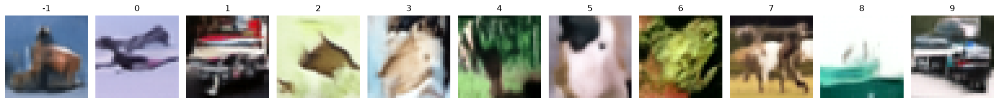

In [13]:
from common.utils import plot_images


imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    eta=1., 
    steps=1_000, 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 1/1000

Steps: 2/1000

Steps: 3/1000

Steps: 4/1000

Steps: 5/1000

...

Steps: 996/1000

Steps: 997/1000

Steps: 998/1000

Steps: 999/1000

Steps: 1000/1000

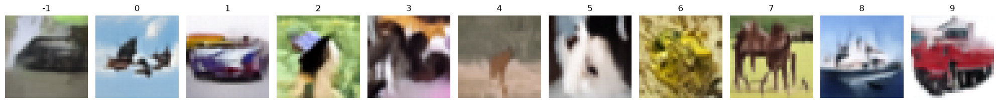

In [14]:
imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    steps=1_000, 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 1/50

Steps: 2/50

Steps: 3/50

Steps: 4/50

Steps: 5/50

...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

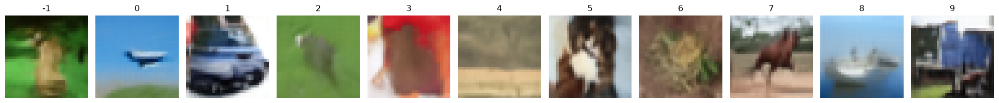

In [15]:
imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 1/50

Steps: 2/50

Steps: 3/50

Steps: 4/50

Steps: 5/50

...

Steps: 46/50

Steps: 47/50

Steps: 48/50

Steps: 49/50

Steps: 50/50

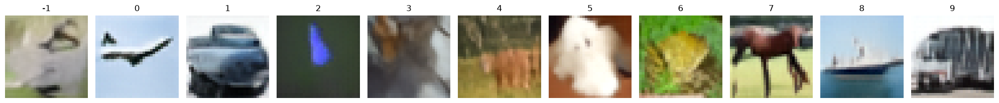

In [16]:
imgs = model.sample(
    add_null_label=True, 
    scale=4., 
    verbose=True
)
plot_images(imgs, has_null_label=True)

## Training history


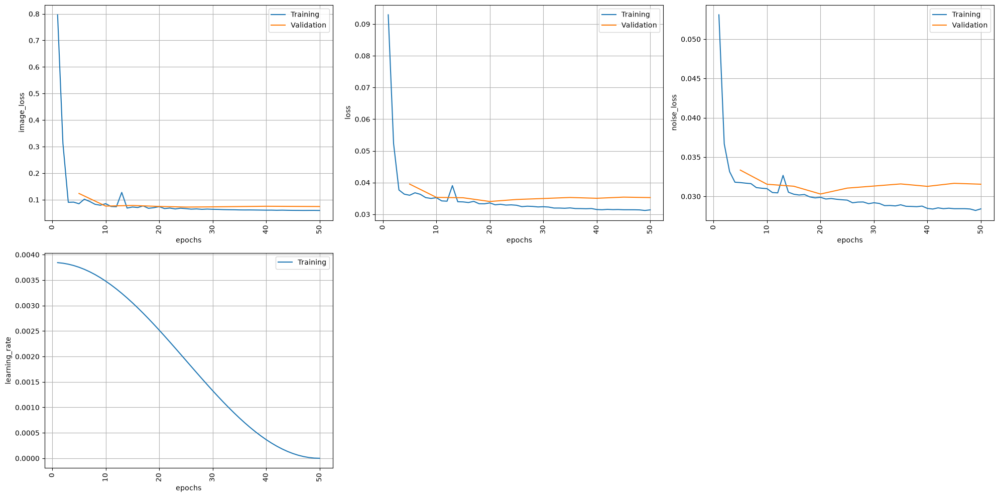

In [17]:
from common.utils import plot_history


plot_history(history, show_all_x_ticks=False)

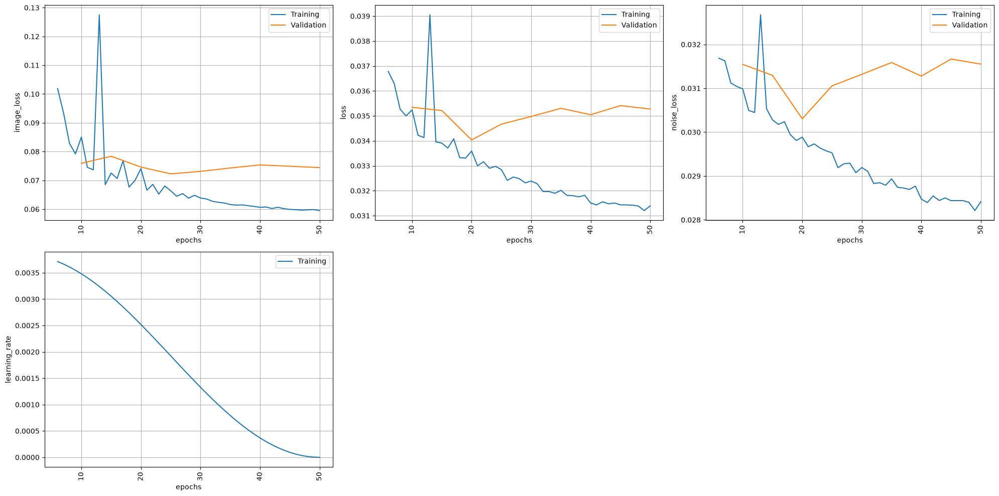

In [18]:
plot_history(history, show_all_x_ticks=False, range_=(5, None))

In [19]:
import json
import numpy as np
from pathlib import Path


if epochs != 50 or len(history["loss"]) != 50:
    raise RuntimeError("The requested fifty training epochs did not complete.")
if not all(np.all(np.isfinite(values)) for values in history.values()):
    raise RuntimeError("Training history contains non-finite values.")
if not np.all(np.isfinite(imgs)):
    raise RuntimeError("The final sample batch contains non-finite values.")
Path('/workspace/cifar10_dit_three_v2_20261011/notebook-3/history.json').write_text(json.dumps({key: [float(value) for value in values] for key, values in history.items()}, indent=2))
print("Completed all 50 epochs, evaluations, sampling cells and finite-history audit.")


Completed all 50 epochs, evaluations, sampling cells and finite-history audit.
